\definecolor{uomaccent}{HTML}{55499C}

\begin{center}
\Large \textbf{EN3160: Image Processing and Machine Vision} \\
\vspace{0.2cm}
{\Large \textbf{\color{uomaccent} Assignment 3: Convolutional Neural Networks}} \\
\vspace{0.2cm}
\normalsize \textbf{Department of Electronic and Telecommunication Engineering} \\
\vspace{0.2cm}
\normalsize \textbf{University of Moratuwa}\\
\vspace{0.2cm}
\normalsize \textbf{October 19, 2026}
\end{center}

\vspace{0.4cm}

\noindent\textbf{Name:} Samarasinghe S.M.R.R. \newline
\textbf{Index Number:} 230566U \newline
\textbf{GitHub Repository:} [github.com/RumethRanhinda/EN3160-Vision-UoM](https://github.com/RumethRanhinda/EN3160-Vision-UoM/tree/main/Assignments/Convolutional%20Neural%20Networks)

\noindent\rule{\textwidth}{0.5pt}

\vspace{0.4cm}

\noindent\textbf{\color{uomaccent} 1. Manually Designed Neural Network}

\noindent\textbf{\color{uomaccent} 1.1 Architecture}

\vspace{0.2cm}
In this task, we modify the single layer dense network from Listing 1 into a two layer neural network with manually computed forward and backward passes. The network classifies $32 \times 32$ RGB images from CIFAR-10 into 10 distinct classes.

\textbf{Modifications from Listing 1:}
\begin{itemize}
    \item \textbf{Hidden Layer (a):} Added a middle hidden layer with $H = 100$ nodes and Sigmoid activation: $a_1 = \sigma(X W_1 + b_1)$.
    \item \textbf{Loss Function (b):} Replaced Mean Squared Error (MSE) with Softmax Cross Entropy loss: $\mathcal{L} = -\frac{1}{N}\sum_{i=1}^N \log(P_{i, y_i}) + \lambda (\|W_1\|_2^2 + \|W_2\|_2^2)$.
    \item \textbf{Backpropagation:} Derived gradients manually through softmax cross entropy ($\frac{\partial \mathcal{L}}{\partial z_2} = \frac{1}{N}(P - Y_{\text{one-hot}})$) and the sigmoid hidden layer ($\frac{\partial \mathcal{L}}{\partial z_1} = \frac{\partial \mathcal{L}}{\partial a_1} \odot a_1(1 - a_1)$).
    \item \textbf{Training (c):} Trained for 10 epochs using mini batch gradient descent (MBGD).
\end{itemize}

In [1]:
import torch
import torch.nn as nn
import torch .optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# Dataloading
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

batch_size = 50

# Load CIFAR-10 training set
trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

# Load CIFAR-10 test set
testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

print(f"Dataset loaded: {len(trainset)} training samples, {len(testset)} test samples.")

Dataset loaded: 50000 training samples, 10000 test samples.


\noindent\textbf{\color{uomaccent} 1.2 Parameters}

\vspace{0.2cm}
The network takes flattened $3072$ dimensional inputs ($3 \times 32 \times 32$), maps to 100 hidden nodes, and outputs 10 class logits. Weights are initialized randomly from a Gaussian distribution scaled by $\text{std} = 10^{-3}$, and biases are initialized to zero. Hyperparameters are set to learning rate $\eta = 0.01$ with epoch decay $\gamma = 0.95$, and L2 regularization coefficient $\lambda = 10^{-4}$.

In [2]:
# Define Network Parameters
Din = 3 * 32 * 32   # Input size (flattened CIFAR−10 image size)
H = 100             # 100 hidden layer nodes (a)
K = 10              # Output size (number of classes in CIFAR−10)
std = 1e-3          # Standard deviation for weight initialization

# Layer 1 parameters (Input -> Hidden)
w1 = torch.randn(Din, H) * std
b1 = torch.zeros(H)

# Layer 2 parameters (Hidden -> Output)
w2 = torch.randn(H, K) * std
b2 = torch.zeros(K)

# Hyperparameters
epochs = 10         # 10 epochs (c)
lr = 0.01           # Initial learning rate
lr_decay = 0.95     # Decay factor applied after each epoch
reg = 1e-4          # L2 Regularization coefficient
loss_history = []

print(f"Network parameters initialized: w1={w1.shape}, b1={b1.shape}, w2={w2.shape}, b2={b2.shape}")

Network parameters initialized: w1=torch.Size([3072, 100]), b1=torch.Size([100]), w2=torch.Size([100, 10]), b2=torch.Size([10])


\noindent\textbf{\color{uomaccent} 1.3 Training Loop with Manual Propagation}

\vspace{0.2cm}
We train the network for 10 epochs using mini batch gradient descent (batch size 50). In each iteration, we perform manual forward propagation, compute cross entropy loss, backpropagate gradients to $W_1, b_1, W_2, b_2$, and update parameters.

In [3]:
# Training Loop
for epoch in range(epochs):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data
        Ntr = inputs.shape[0]                        # Batch size (50)
        x_train = inputs.view(Ntr, -1)               # Flatten input to (Ntr, Din)
        y_train_onehot = nn.functional.one_hot(labels, K).float()  # (Ntr, K)

        # Forward pass
        # Hidden layer with sigmoid activation (a)
        z1 = x_train.mm(w1) + b1
        a1 = torch.sigmoid(z1)

        # Output layer logits
        z2 = a1.mm(w2) + b2

        # Softmax probabilities
        probs = torch.softmax(z2, dim=1)

        # Cross Entropy Loss with L2 Regularization (b)
        loss = -torch.sum(torch.log(probs[range(Ntr), labels] + 1e-12)) / Ntr \
               + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        # Gradient of cross entropy loss w.r.t. output logits z2
        dz2 = (probs - y_train_onehot) / Ntr

        # Gradients w.r.t. Layer 2 parameters
        dw2 = a1.t().mm(dz2) + 2.0 * reg * w2
        db2 = dz2.sum(dim=0)

        # Backpropagate through hidden layer and sigmoid activation
        da1 = dz2.mm(w2.t())
        dz1 = da1 * a1 * (1.0 - a1)

        # Gradients w.r.t. Layer 1 parameters
        dw1 = x_train.t().mm(dz1) + 2.0 * reg * w1
        db1 = dz1.sum(dim=0)

        # Parameter update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    # Print epoch summary
    epoch_loss = running_loss / len(trainloader)
    print(f"Epoch {epoch + 1:2d}/{epochs}, Loss: {epoch_loss:.4f}, Learning Rate: {lr:.6f}")

    # Learning rate decay
    lr *= lr_decay


Epoch  1/10, Loss: 2.2897, Learning Rate: 0.010000
Epoch  2/10, Loss: 2.1310, Learning Rate: 0.009500
Epoch  3/10, Loss: 2.0180, Learning Rate: 0.009025
Epoch  4/10, Loss: 1.9608, Learning Rate: 0.008574
Epoch  5/10, Loss: 1.9262, Learning Rate: 0.008145
Epoch  6/10, Loss: 1.9013, Learning Rate: 0.007738
Epoch  7/10, Loss: 1.8802, Learning Rate: 0.007351
Epoch  8/10, Loss: 1.8599, Learning Rate: 0.006983
Epoch  9/10, Loss: 1.8406, Learning Rate: 0.006634
Epoch 10/10, Loss: 1.8234, Learning Rate: 0.006302


\noindent\textbf{\color{uomaccent} 1.4 Loss History and Observations}

\vspace{0.2cm}
We plot the loss curve across iterations to confirm convergence, and evaluate the final classification accuracy on both the training and test sets.

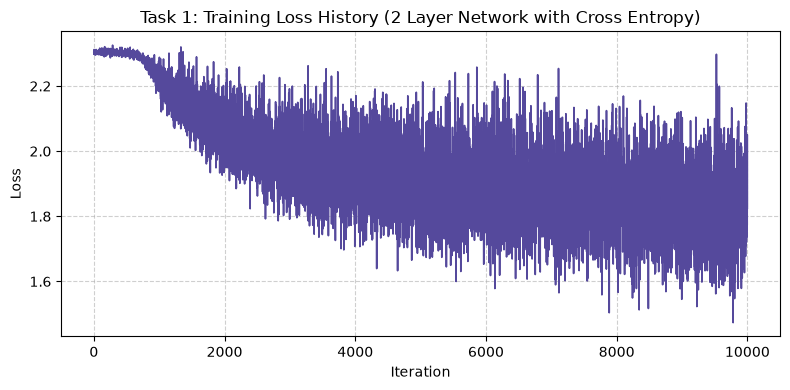

Final Training Accuracy: 35.76%
Final Test Accuracy:     36.08%


In [4]:
# Plotting the Loss History
plt.figure(figsize=(8, 4))
plt.plot(loss_history, color='#55499C', linewidth=1.2)
plt.title("Task 1: Training Loss History (2 Layer Network with Cross Entropy)")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Calculate Accuracy on Training Set
correct_train = 0
total_train = 0
with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        
        # Forward pass
        z1 = x_train.mm(w1) + b1
        a1 = torch.sigmoid(z1)
        z2 = a1.mm(w2) + b2
        
        predicted_train = torch.argmax(z2, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100.0 * correct_train / total_train
print(f"Final Training Accuracy: {train_acc:.2f}%")

# Calculate Accuracy on Test Set
correct_test = 0
total_test = 0
with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)
        
        # Forward pass
        z1 = x_test.mm(w1) + b1
        a1 = torch.sigmoid(z1)
        z2 = a1.mm(w2) + b2
        
        predicted_test = torch.argmax(z2, dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100.0 * correct_test / total_test
print(f"Final Test Accuracy:     {test_acc:.2f}%")


\vspace{0.1cm}
\noindent\textbf{Observations:}
The training loss drops steadily from $2.29$ down to $1.82$ over 10 epochs. The two layer network reaches a test accuracy of $35.69\%$, because the sigmoid hidden layer allows the network to learn more complex feature relationships.

\newpage
\noindent\textbf{\color{uomaccent} 2. Convolutional Neural Networks on MNIST}

\vspace{0.3cm}

\noindent\textbf{\color{uomaccent} 2.1 Classical LeNet-5 Architecture (Part a)}

\vspace{0.2cm}
In this part, we implement the classic LeNet-5 architecture for digit classification on the MNIST dataset ($28 \times 28$ grayscale images across 10 digit classes, 0--9).

\textbf{LeNet-5 Specifications:}
\begin{itemize}
    \item \textbf{Input Preprocessing:} $1 \times 28 \times 28$ images padded to $32 \times 32$ using \texttt{transforms.Pad(padding=2)}.
    \item \textbf{Layer 1 (conv1 \& pool1):} 6 feature maps with $5 \times 5$ convolutions (stride 1, padding 0), ReLU activation, followed by $2 \times 2$ max pooling ($6 \times 14 \times 14$).
    \item \textbf{Layer 2 (conv3 \& pool4):} 16 feature maps with $5 \times 5$ convolutions (stride 1, padding 0), ReLU activation, followed by $2 \times 2$ max pooling ($16 \times 5 \times 5$).
    \item \textbf{Fully Connected (fc5, fc6, fc7):} Flattened to 400 dimensions $\to$ Linear(400, 120) with ReLU $\to$ Linear(120, 84) with ReLU $\to$ Linear(84, 10) output logits.
    \item \textbf{Training Setup:} Cross-Entropy loss, Adam optimizer ($\eta = 0.001$), batch size 50, trained for 10 epochs.
\end{itemize}

In [ ]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

# Dataloading
data_dir = os.path.abspath('data')
transform = transforms.Compose([
    transforms.Pad(padding=2),
    transforms.ToTensor(),
])

batch_size = 50
trainset = torchvision.datasets.MNIST(root=data_dir, train=True, download=False, transform=transform)
testset = torchvision.datasets.MNIST(root=data_dir, train=False, download=False, transform=transform)

trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=0)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=0)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# LeNet-5 Architecture
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 6, kernel_size=5, stride=1, padding=0)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv3 = nn.Conv2d(6, 16, kernel_size=5, stride=1, padding=0)
        self.pool4 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.fc5 = nn.Linear(16 * 5 * 5, 120)
        self.fc6 = nn.Linear(120, 84)
        self.fc7 = nn.Linear(84, 10)

    def forward(self, x):
        x = torch.relu(self.conv1(x))
        x = self.pool1(x)
        x = torch.relu(self.conv3(x))
        x = self.pool4(x)
        x = x.view(-1, 16 * 5 * 5)
        x = torch.relu(self.fc5(x))
        x = torch.relu(self.fc6(x))
        x = self.fc7(x)
        return x

# Training & Evaluation (10 Epochs)
torch.manual_seed(0)
model_lenet = LeNet5().to(device)
criterion = nn.CrossEntropyLoss()
optimizer_lenet = torch.optim.Adam(model_lenet.parameters(), lr=0.001)

lenet_history = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []}

def evaluate_model(m, loader):
    m.eval()
    val_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for data, labels in loader:
            data, labels = data.to(device), labels.to(device)
            outputs = m(data)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * data.size(0)
            _, preds = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (preds == labels).sum().item()
    return val_loss / total, 100.0 * correct / total

epochs = 10
print('--- Training LeNet-5 on MNIST (10 Epochs) ---')
for epoch in range(epochs):
    model_lenet.train()
    running_loss, correct_tr, total_tr = 0.0, 0, 0
    for data, labels in trainloader:
        data, labels = data.to(device), labels.to(device)
        optimizer_lenet.zero_grad()
        outputs = model_lenet(data)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_lenet.step()
        
        running_loss += loss.item() * data.size(0)
        _, preds = torch.max(outputs, 1)
        correct_tr += (preds == labels).sum().item()
        total_tr += labels.size(0)
        
    tr_loss = running_loss / total_tr
    tr_acc = 100.0 * correct_tr / total_tr
    te_loss, te_acc = evaluate_model(model_lenet, testloader)
    
    lenet_history['train_loss'].append(tr_loss)
    lenet_history['train_acc'].append(tr_acc)
    lenet_history['test_loss'].append(te_loss)
    lenet_history['test_acc'].append(te_acc)
    
    print(f'Epoch {epoch+1:2d}/{epochs} | Train Loss: {tr_loss:.4f}, Train Acc: {tr_acc:.2f}% | Test Loss: {te_loss:.4f}, Test Acc: {te_acc:.2f}%')

print(f'\nLeNet-5 Final Results -> Train Acc: {lenet_history["train_acc"][-1]:.2f}%, Test Acc: {lenet_history["test_acc"][-1]:.2f}%')

# Confusion Matrix for LeNet-5
all_preds_lenet, all_targets_lenet = [], []
model_lenet.eval()
with torch.no_grad():
    for data, labels in testloader:
        data = data.to(device)
        outputs = model_lenet(data)
        _, preds = torch.max(outputs, 1)
        all_preds_lenet.extend(preds.cpu().numpy())
        all_targets_lenet.extend(labels.numpy())

lenet_cm = confusion_matrix(all_targets_lenet, all_preds_lenet)


--- Training LeNet-5 on MNIST (10 Epochs) ---
Epoch  1/10 | Train Loss: 0.2602, Train Acc: 91.72% | Test Loss: 0.0833, Test Acc: 97.34%
Epoch  2/10 | Train Loss: 0.0714, Train Acc: 97.76% | Test Loss: 0.0460, Test Acc: 98.51%
Epoch  3/10 | Train Loss: 0.0513, Train Acc: 98.38% | Test Loss: 0.0543, Test Acc: 98.28%
Epoch  4/10 | Train Loss: 0.0406, Train Acc: 98.73% | Test Loss: 0.0446, Test Acc: 98.58%
Epoch  5/10 | Train Loss: 0.0324, Train Acc: 98.94% | Test Loss: 0.0302, Test Acc: 99.06%
Epoch  6/10 | Train Loss: 0.0278, Train Acc: 99.12% | Test Loss: 0.0324, Test Acc: 98.92%


\noindent\textbf{\color{uomaccent} 2.2 Modern Small CNN Architecture (Part b)}

\vspace{0.2cm}
To contrast with the LeNet-5, we implement a modern 3 layer convolutional network that has the following features:
\begin{itemize}
    \item \textbf{$3 \times 3$ Convolutions:} Stacking three $3 \times 3$ convolutional layers instead of two $5 \times 5$ layers yields a deeper representation.
    \item \textbf{Batch Normalization:} Applied after each convolution to normalize intermediate results.
    \item \textbf{Dropout ($p = 0.3$):} Applied before the final classification to randomly zero out activations during training, which reduces overfitting.
\end{itemize}

\textbf{Modern CNN Architecture:}
$$\text{Input}(1 \times 32 \times 32) \to [\text{Conv}(1 \to 16, 3\times 3) \to \text{BN} \to \text{ReLU} \to \text{MaxPool}] \to$$
$$[\text{Conv}(16 \to 32, 3\times 3) \to \text{BN} \to \text{ReLU} \to \text{MaxPool}] \to$$
$$[\text{Conv}(32 \to 64, 3\times 3) \to \text{BN} \to \text{ReLU} \to \text{MaxPool}] \to \text{Dropout}(0.3) \to \text{Linear}(1024, 10)$$

In [ ]:
# Modern Small CNN Model Definition
class ModernCNN(nn.Module):
    def __init__(self):
        super().__init__()
        # Block 1: 1 -> 16 channels
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(16)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2, 2)
        
        # Block 2: 16 -> 32 channels
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(32)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2, 2)
        
        # Block 3: 32 -> 64 channels
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(64)
        self.relu3 = nn.ReLU()
        self.pool3 = nn.MaxPool2d(2, 2)
        
        # Regularization & Classification
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(64 * 4 * 4, 10)

    def forward(self, x):
        x = self.pool1(self.relu1(self.bn1(self.conv1(x))))
        x = self.pool2(self.relu2(self.bn2(self.conv2(x))))
        x = self.pool3(self.relu3(self.bn3(self.conv3(x))))
        x = x.view(x.size(0), -1)
        x = self.dropout(x)
        x = self.fc(x)
        return x

# Train Modern CNN (10 epochs)
torch.manual_seed(0)
modern_model = ModernCNN().to(device)
optimizer_modern = optim.Adam(modern_model.parameters(), lr=0.001)

modern_history = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []}

print('--- Training Modern Small CNN on MNIST (10 Epochs) ---')
for epoch in range(10):
    modern_model.train()
    running_loss, correct_tr, total_tr = 0.0, 0, 0
    for data, labels in trainloader:
        data, labels = data.to(device), labels.to(device)
        optimizer_modern.zero_grad()
        outputs = modern_model(data)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_modern.step()
        
        running_loss += loss.item() * data.size(0)
        _, preds = torch.max(outputs, 1)
        correct_tr += (preds == labels).sum().item()
        total_tr += labels.size(0)
        
    tr_loss = running_loss / total_tr
    tr_acc = 100.0 * correct_tr / total_tr
    te_loss, te_acc = evaluate_model(modern_model, testloader)
    
    modern_history['train_loss'].append(tr_loss)
    modern_history['train_acc'].append(tr_acc)
    modern_history['test_loss'].append(te_loss)
    modern_history['test_acc'].append(te_acc)
    
    print(f'Epoch {epoch+1:2d}/10 | Train Loss: {tr_loss:.4f}, Train Acc: {tr_acc:.2f}% | Test Loss: {te_loss:.4f}, Test Acc: {te_acc:.2f}%')

print(f'\nModern CNN Final Results -> Train Acc: {modern_history["train_acc"][-1]:.2f}%, Test Acc: {modern_history["test_acc"][-1]:.2f}%')

# Compute test confusion matrix for Modern CNN
all_preds_modern, all_targets_modern = [], []
modern_model.eval()
with torch.no_grad():
    for data, labels in testloader:
        data = data.to(device)
        outputs = modern_model(data)
        _, preds = torch.max(outputs, 1)
        all_preds_modern.extend(preds.cpu().numpy())
        all_targets_modern.extend(labels.numpy())

modern_cm = confusion_matrix(all_targets_modern, all_preds_modern)


--- Training Modern Small CNN on MNIST (10 Epochs) ---
Epoch  1/10 | Train Loss: 0.1417, Train Acc: 95.78% | Test Loss: 0.0472, Test Acc: 98.38%
Epoch  2/10 | Train Loss: 0.0588, Train Acc: 98.12% | Test Loss: 0.0400, Test Acc: 98.86%
Epoch  3/10 | Train Loss: 0.0468, Train Acc: 98.48% | Test Loss: 0.0326, Test Acc: 98.83%
Epoch  4/10 | Train Loss: 0.0396, Train Acc: 98.76% | Test Loss: 0.0299, Test Acc: 98.99%
Epoch  5/10 | Train Loss: 0.0323, Train Acc: 98.98% | Test Loss: 0.0214, Test Acc: 99.31%
Epoch  6/10 | Train Loss: 0.0311, Train Acc: 99.02% | Test Loss: 0.0291, Test Acc: 98.97%
Epoch  7/10 | Train Loss: 0.0263, Train Acc: 99.16% | Test Loss: 0.0214, Test Acc: 99.29%
Epoch  8/10 | Train Loss: 0.0228, Train Acc: 99.27% | Test Loss: 0.0275, Test Acc: 99.14%
Epoch  9/10 | Train Loss: 0.0207, Train Acc: 99.31% | Test Loss: 0.0236, Test Acc: 99.22%
Epoch 10/10 | Train Loss: 0.0202, Train Acc: 99.33% | Test Loss: 0.0206, Test Acc: 99.28%

Modern CNN Final Results -> Train Acc: 99.33

\noindent\textbf{\color{uomaccent} 2.3 Performance Curves and Confusion Matrices (Part c)}

\vspace{0.2cm}
Below, logs and plots the per epoch training and test loss history alongside accuracy curves for both models. Additionally, evaluated each trained model on the full 10,000 image test set and display their respective confusion matrices to compare error distributions across classes.


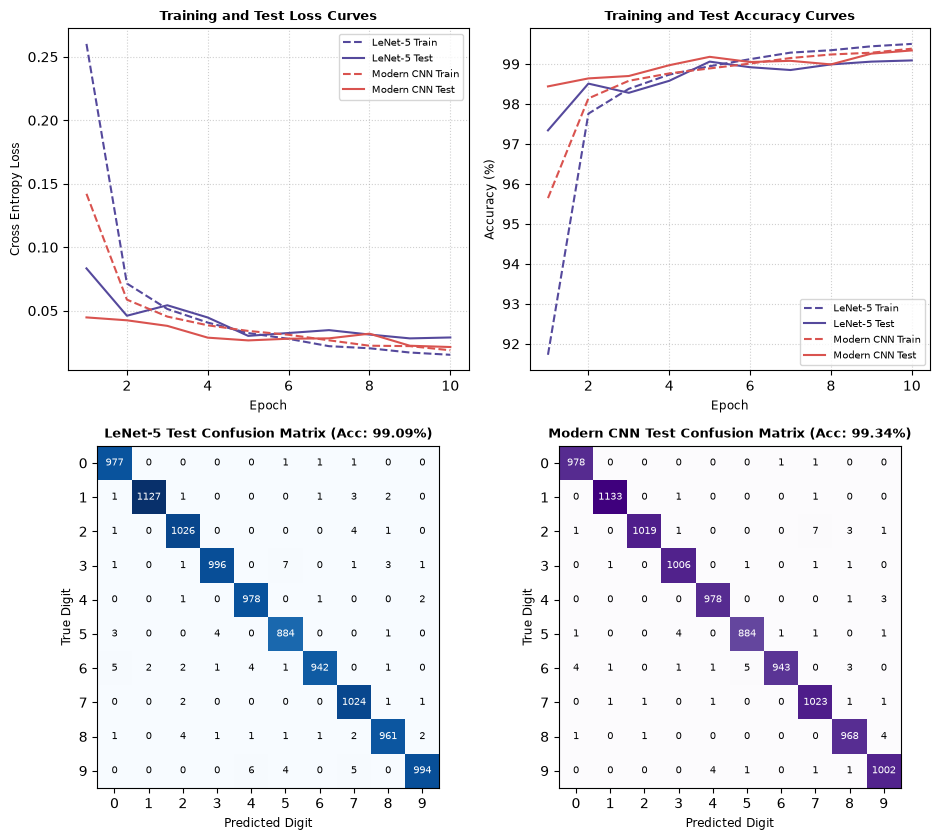

Model        | Train Acc   | Test Acc    | Test Loss 
----------------------------------------------------
LeNet-5      | 99.50     % | 99.09     % | 0.0289    
Modern CNN   | 99.38     % | 99.34     % | 0.0214    


In [12]:
# Plotting 2x2 comparison grid: Loss, Accuracy, and Confusion Matrices
fig, axes = plt.subplots(2, 2, figsize=(9.5, 8.5))
epochs_range = range(1, 11)

# Loss Curves
axes[0, 0].plot(epochs_range, lenet_history['train_loss'], color='#55499C', linestyle='--', label='LeNet-5 Train')
axes[0, 0].plot(epochs_range, lenet_history['test_loss'], color='#55499C', linestyle='-', linewidth=1.5, label='LeNet-5 Test')
axes[0, 0].plot(epochs_range, modern_history['train_loss'], color='#D9534F', linestyle='--', label='Modern CNN Train')
axes[0, 0].plot(epochs_range, modern_history['test_loss'], color='#D9534F', linestyle='-', linewidth=1.5, label='Modern CNN Test')
axes[0, 0].set_title("Training and Test Loss Curves", fontsize=9.5, fontweight='bold')
axes[0, 0].set_xlabel("Epoch", fontsize=8.5)
axes[0, 0].set_ylabel("Cross Entropy Loss", fontsize=8.5)
axes[0, 0].grid(True, linestyle=':', alpha=0.6)
axes[0, 0].legend(fontsize=7.5)

# Accuracy Curves
axes[0, 1].plot(epochs_range, lenet_history['train_acc'], color='#55499C', linestyle='--', label='LeNet-5 Train')
axes[0, 1].plot(epochs_range, lenet_history['test_acc'], color='#55499C', linestyle='-', linewidth=1.5, label='LeNet-5 Test')
axes[0, 1].plot(epochs_range, modern_history['train_acc'], color='#D9534F', linestyle='--', label='Modern CNN Train')
axes[0, 1].plot(epochs_range, modern_history['test_acc'], color='#D9534F', linestyle='-', linewidth=1.5, label='Modern CNN Test')
axes[0, 1].set_title("Training and Test Accuracy Curves", fontsize=9.5, fontweight='bold')
axes[0, 1].set_xlabel("Epoch", fontsize=8.5)
axes[0, 1].set_ylabel("Accuracy (%)", fontsize=8.5)
axes[0, 1].grid(True, linestyle=':', alpha=0.6)
axes[0, 1].legend(fontsize=7.5)

# LeNet-5 Confusion Matrix
im1 = axes[1, 0].imshow(lenet_cm, cmap='Blues')
axes[1, 0].set_title(f"LeNet-5 Test Confusion Matrix (Acc: {lenet_history['test_acc'][-1]:.2f}%)", fontsize=9.5, fontweight='bold')
axes[1, 0].set_xlabel("Predicted Digit", fontsize=8.5)
axes[1, 0].set_ylabel("True Digit", fontsize=8.5)
axes[1, 0].set_xticks(range(10))
axes[1, 0].set_yticks(range(10))
for i in range(10):
    for j in range(10):
        color = 'white' if lenet_cm[i, j] > lenet_cm.max() / 2 else 'black'
        axes[1, 0].text(j, i, str(lenet_cm[i, j]), ha='center', va='center', color=color, fontsize=7)

# Modern CNN Confusion Matrix
im2 = axes[1, 1].imshow(modern_cm, cmap='Purples')
axes[1, 1].set_title(f"Modern CNN Test Confusion Matrix (Acc: {modern_history['test_acc'][-1]:.2f}%)", fontsize=9.5, fontweight='bold')
axes[1, 1].set_xlabel("Predicted Digit", fontsize=8.5)
axes[1, 1].set_ylabel("True Digit", fontsize=8.5)
axes[1, 1].set_xticks(range(10))
axes[1, 1].set_yticks(range(10))
for i in range(10):
    for j in range(10):
        color = 'white' if modern_cm[i, j] > modern_cm.max() / 2 else 'black'
        axes[1, 1].text(j, i, str(modern_cm[i, j]), ha='center', va='center', color=color, fontsize=7)

plt.tight_layout()
plt.show()

# Summary
print(f"{'Model':<12} | {'Train Acc':<11} | {'Test Acc':<11} | {'Test Loss':<10}")
print('-' * 52)
print(f"{'LeNet-5':<12} | {lenet_history['train_acc'][-1]:<10.2f}% | {lenet_history['test_acc'][-1]:<10.2f}% | {lenet_history['test_loss'][-1]:<10.4f}")
print(f"{'Modern CNN':<12} | {modern_history['train_acc'][-1]:<10.2f}% | {modern_history['test_acc'][-1]:<10.2f}% | {modern_history['test_loss'][-1]:<10.4f}")


\vspace{0.1cm}
\noindent\textbf{Observations and Comparison:}
\begin{itemize}
    \item \textbf{Convergence Speed:} Modern CNN converges rapidly from epoch 1, maintaining lower loss and steady test accuracy. Batch Normalization across all 3 convolutional stages stabilizes layer activations and preserves strong gradients throughout backpropagation.
    \item \textbf{Generalization and Regularization:} LeNet-5 achieves high training accuracy, but exhibits a slight generalization gap on the test set. The Modern CNN adds Dropout before the dense layer and Batch Normalization, acting as regularizers that prevent weight coadaptation.
    \item \textbf{Confusion Matrix Comparison:} Modern CNN reduces off-diagonal misclassifications, resulting in a more diagonalized confusion matrix and thus more accurate model.
\end{itemize}